###EXPERIMENT NO. 6
### ADVANCED DATA VISUALIZATION USING MATPLOTLIB AND SEABORN

### Name       : Akshit Negi
### UID        : CU24250214
### Course     : B.Tech CSE
### Section    : CSE "B"
### Roll No.   : 04

### AIM
### To develop a Linear Regression model for predicting Sales using
### advertising expenditure on TV, Radio and Newspaper and evaluate
### the model using appropriate regression performance metrics.


STEP 1: IMPORT LIBRARIES

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tkinter as tk

from tkinter import filedialog
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


STEP 2: LOAD DATASET

In [13]:
from google.colab import files
import io

uploaded = files.upload()

if not uploaded:
    print("No file selected.")
else:
    for filename in uploaded.keys():
        # Assuming the uploaded file is a CSV
        df = pd.read_csv(io.StringIO(uploaded[filename].decode('utf-8')))
        print("Dataset loaded successfully!")
        print("Shape:", df.shape)
        break # Assuming only one file is uploaded or we take the first one

Saving Advertising.csv to Advertising (1).csv
Dataset loaded successfully!
Shape: (200, 5)


STEP 3: DATA PREPROCESSING

In [14]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Handle missing values if present
df = df.dropna()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (200, 4)
Columns: ['TV', 'radio', 'newspaper', 'sales']


STEP 4: SELECT FEATURES AND TARGET

In [15]:
X = df[
    [
        "TV",
        "radio",
        "newspaper"
    ]
]

y = df["sales"]

STEP 5: SPLIT DATASET INTO TRAINING AND TESTING SETS

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


STEP 6: TRAIN LINEAR REGRESSION MODEL

In [17]:
model = LinearRegression()

model.fit(X_train, y_train)

# ================================================================
# STEP 7: PREDICT SALES
# ================================================================

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

print("\nActual vs Predicted Sales:")
print(results.head(10))


Actual vs Predicted Sales:
   Actual Sales  Predicted Sales
0          16.9        16.408024
1          22.4        20.889882
2          21.4        21.553843
3           7.3        10.608503
4          24.7        22.112373
5          12.6        13.105592
6          22.3        21.057192
7           8.4         7.461010
8          11.5        13.606346
9          14.9        15.155070


STEP 8: MODEL PERFORMANCE EVALUATION

In [18]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nModel Performance:")
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))


Model Performance:
MAE : 1.4608
MSE : 3.1741
RMSE: 1.7816
R²  : 0.8994


STEP 9: REGRESSION COEFFICIENTS

In [19]:
print("\nRegression Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 4))

print("Intercept:", round(model.intercept_, 4))


Regression Coefficients:
TV : 0.0447
radio : 0.1892
newspaper : 0.0028
Intercept: 2.9791


STEP 10: REGRESSION EQUATION

In [20]:
print("\nRegression Equation:")

print(
    f"Sales = {model.intercept_:.4f} "
    f"+ ({model.coef_[0]:.4f} × TV) "
    f"+ ({model.coef_[1]:.4f} × Radio) "
    f"+ ({model.coef_[2]:.4f} × Newspaper)"
)


Regression Equation:
Sales = 2.9791 + (0.0447 × TV) + (0.1892 × Radio) + (0.0028 × Newspaper)


STEP 11: ACTUAL VS PREDICTED SALES

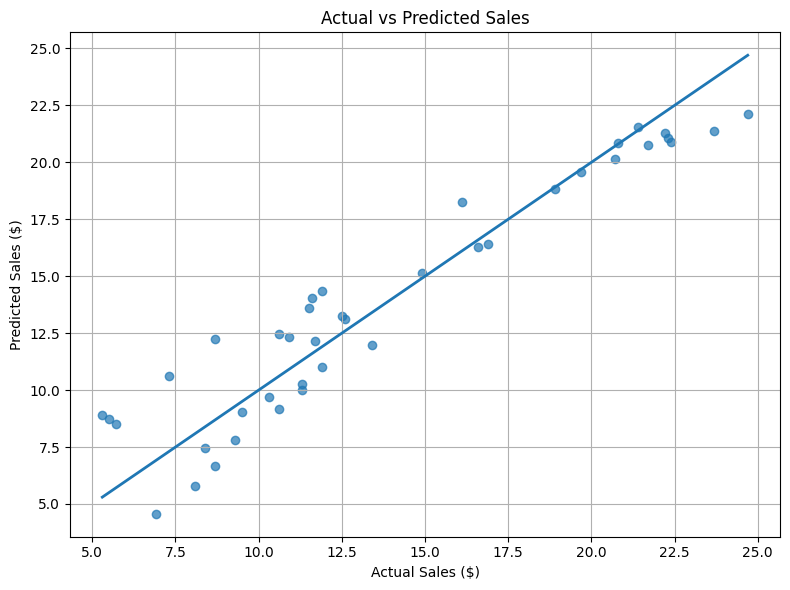

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linewidth=2
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales ($)")
plt.ylabel("Predicted Sales ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

 STEP 12: TV ADVERTISING VS SALES

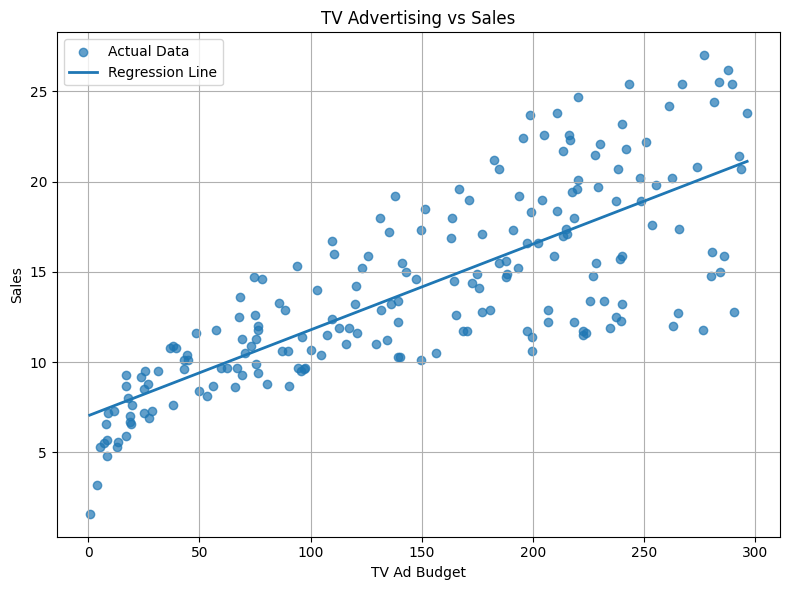

In [22]:
tv_model = LinearRegression()

tv_model.fit(
    df[["TV"]],
    y
)

tv_pred = tv_model.predict(
    df[["TV"]]
)

sort_index = np.argsort(
    df["TV"].values
)

plt.figure(figsize=(8, 6))

plt.scatter(
    df["TV"],
    y,
    alpha=0.7,
    label="Actual Data"
)

plt.plot(
    df["TV"].values[sort_index],
    tv_pred[sort_index],
    linewidth=2,
    label="Regression Line"
)

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Ad Budget")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

STEP 13: ACTUAL VS PREDICTED COMPARISON

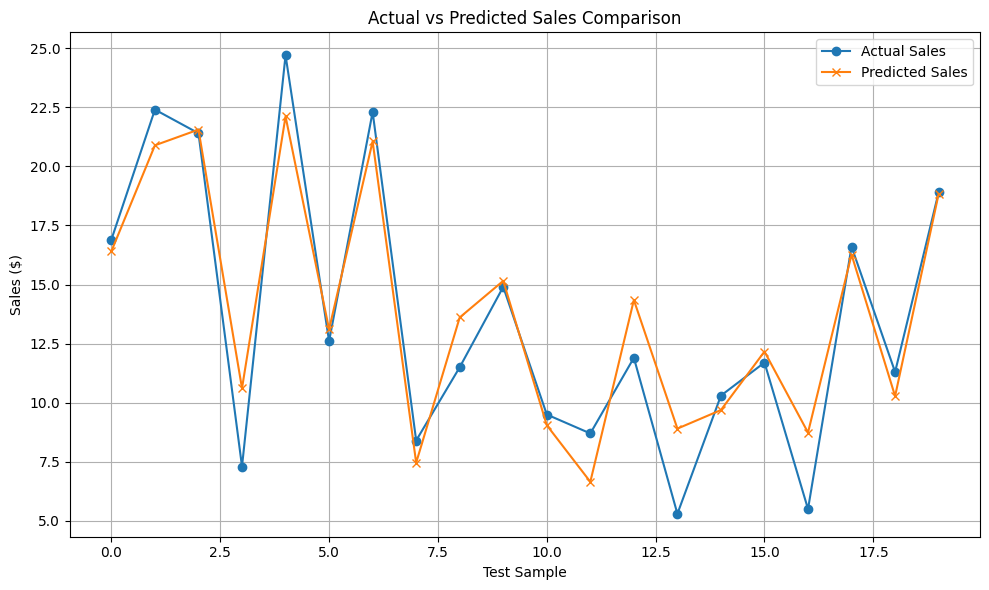

In [23]:

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).reset_index(drop=True)

comparison = comparison.head(20)

plt.figure(figsize=(10, 6))

plt.plot(
    comparison.index,
    comparison["Actual"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    comparison.index,
    comparison["Predicted"],
    marker="x",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales Comparison")
plt.xlabel("Test Sample")
plt.ylabel("Sales ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


STEP 14: REGRESSION COEFFICIENT VISUALIZATION

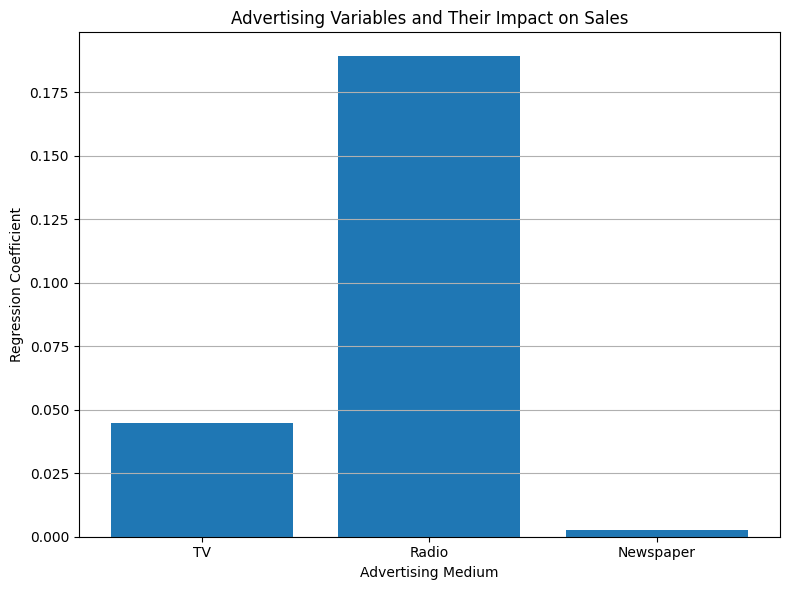

In [24]:
plt.figure(figsize=(8, 6))

plt.bar(
    ["TV", "Radio", "Newspaper"],
    model.coef_
)

plt.title("Advertising Variables and Their Impact on Sales")
plt.xlabel("Advertising Medium")
plt.ylabel("Regression Coefficient")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

STEP 15: MODEL INTERPRETATION

In [25]:
coefficient_series = pd.Series(
    model.coef_,
    index=X.columns
)

most_influential = coefficient_series.abs().idxmax()

print("\nMost influential feature:", most_influential)

if r2 >= 0.80:
    print("The model has strong predictive performance.")
elif r2 >= 0.50:
    print("The model has moderate predictive performance.")
else:
    print("The model has limited predictive performance.")


Most influential feature: radio
The model has strong predictive performance.


QUESTIONS AND ANSWERS

Q1. What is Predictive Analytics, and how is it used in real-world applications?

Answer:
Predictive Analytics is the process of using historical data, statistical methods and machine learning algorithms to predict future outcomes.

It is used in:

Sales forecasting

Demand prediction

Customer behavior prediction

Risk analysis

Financial forecasting

In this experiment, Predictive Analytics is used to predict Sales based on advertising expenditure.

Q2. Explain the working principle of the Linear Regression algorithm.

Answer:
Linear Regression establishes a mathematical relationship between independent variables and a dependent variable.

The general equation is:
Y = b0 + b1X1 + b2X2 + b3X3

In this experiment:
Sales = b0 + b1(TV) + b2(Radio) + b3(Newspaper)

The model learns the coefficients from the training data and uses them to predict Sales.

Q3. Differentiate between dependent and independent variables with suitable examples.

Answer:
Independent variables are the variables used to make predictions.
The dependent variable is the variable that is being predicted.

In this experiment:
Independent Variables:

TV Ad Budget

Radio Ad Budget

Newspaper Ad Budget

Dependent Variable:

Sales

Q4. Why is it necessary to split the dataset into training and testing sets?

Answer:
The training dataset is used to train the model, while the testing dataset is used to evaluate the model on unseen data.
This helps determine whether the model can generalize to new observations.
In this experiment, 80% of the data is used for training and 20% is used for testing.

Q5. What is the significance of the R² Score in regression analysis?

Answer:
R², or the Coefficient of Determination, measures how much variation in the dependent variable is explained by the regression model.
A higher R² generally indicates that the model explains a larger proportion of the variation in the target variable.
An R² value closer to 1 indicates stronger explanatory performance.

Q6. Differentiate between MAE, MSE, and RMSE. Which metric is more sensitive to large prediction errors?

Answer:

MAE (Mean Absolute Error) calculates the average absolute difference between actual and predicted values.

MSE (Mean Squared Error) calculates the average squared prediction error.

RMSE (Root Mean Squared Error) is the square root of MSE.

MSE and RMSE are more sensitive to large prediction errors because the errors are squared.

Q7. What assumptions should be satisfied before applying Linear Regression?

Answer:
The major assumptions are:

There should be a linear relationship between variables.

Observations should be independent.

The variance of errors should be approximately constant.

Errors should be approximately normally distributed for statistical inference.

Independent variables should not have severe multicollinearity.

Q8. How can overfitting and underfitting affect the performance of a regression model?

Answer:
Overfitting occurs when the model learns the training data too closely, including noise, and may perform poorly on unseen data.
Underfitting occurs when the model is too simple and fails to capture important patterns in the dataset.
A good model should achieve a suitable balance between complexity and generalization.

Q9. Mention any three real-world applications of Linear Regression in business or industry.

Answer:

Sales forecasting: Predicting future sales using advertising expenditure.

House price prediction: Predicting house prices using area, location and other numerical features.

Demand forecasting: Predicting future product demand using historical data.

Other applications include revenue prediction, cost estimation and financial forecasting.

Q10. How can feature selection improve the accuracy and interpretability of a predictive model?

Answer:
Feature selection removes irrelevant or redundant variables from the dataset.
It can:

Reduce model complexity

Reduce noise

Improve generalization

Reduce computation time

Improve interpretability

In this experiment, selecting TV, Radio and Newspaper advertising budgets provides relevant variables for predicting Sales.

END OF EXPERIMENT 6